# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3 * 1) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (frame_mb * frames_per_day * 400) / (1024 ** 2)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frame_mb_small = (640 * 360 * 3 * 1) / (1024 ** 2)
frames_per_day_small = 10 * 24 * 3600
fleet_tb_small = (frame_mb_small * frames_per_day_small * 400) / (1024 ** 2)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_
Spatial - at 360p a license plate or a person's face would probably just be a blurry smear of a few pixels, so stuff like reading a plate number or identifying a face would become impossible once you downsample, you cant get that detail back later no matter how much you interpolate/upscale it. Temporal - at only 10fps, fast motion between frames (like someone running, or a car door opening quickly) would have bigger gaps between samples, so you could lose the exact moment an event happened or get motion blur/skipped frames that make it look like things teleported, which hurts the correspondence between what happened and what the frames show.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

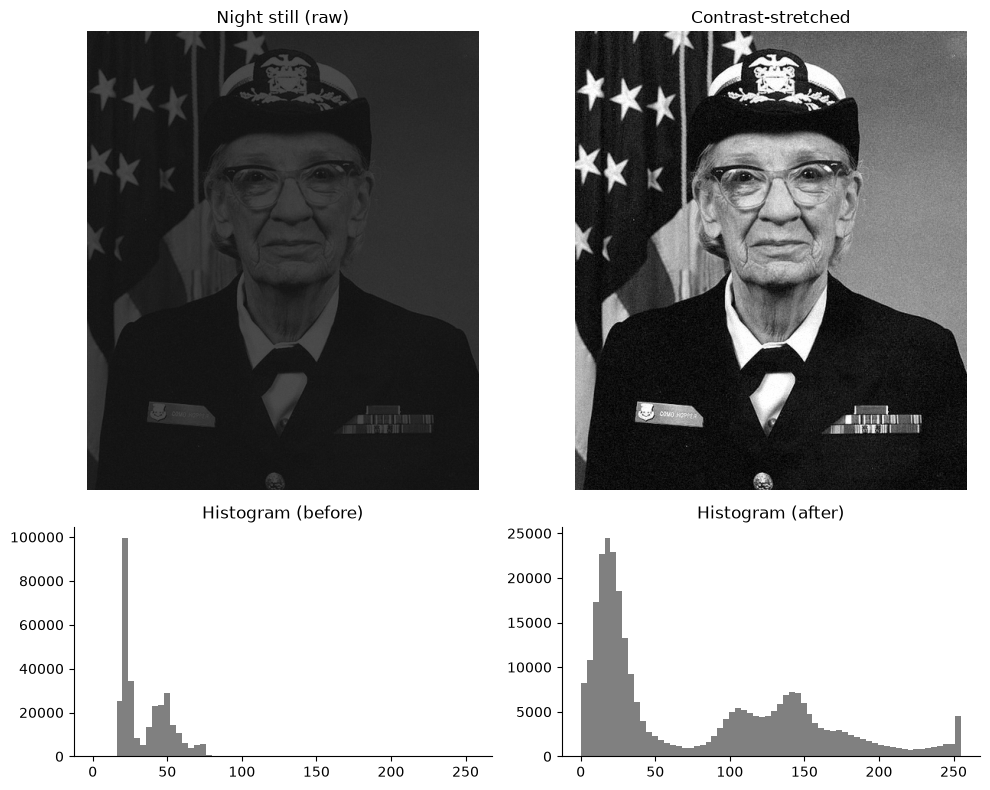

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Night still (raw)"); axes[0, 0].axis("off")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched"); axes[0, 1].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="grey")
axes[1, 0].set_title("Histogram (before)")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="grey")
axes[1, 1].set_title("Histogram (after)")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
The raw histogram is a narrow/low-contrast histogram - basically all the pixel values are bunched up in a small range near the dark end instead of spread across 0-255, which is why the image looks murky and flat. Stretching remaps that narrow occupied range to use the full 0-255 scale, so the same relative differences between pixels now look much bigger to our eyes - no new detail was actually captured by the camera, we just made the existing differences easier for a human to see. A histogram alone cant tell you what's in the image because it only counts how many pixels have each value, it throws away all the spatial/positional information - two completely different images (like a face and a texture of random noise) could technically have the exact same histogram if they happen to use the same intensity values in different counts, so you genuinely need to look at the image itself.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing: 68.70s to 78.10s
running: 78.60s to 86.00s
audio event at frame 2250 (t=75.00s)
lighting event at frame 3000 (t=100.00s)


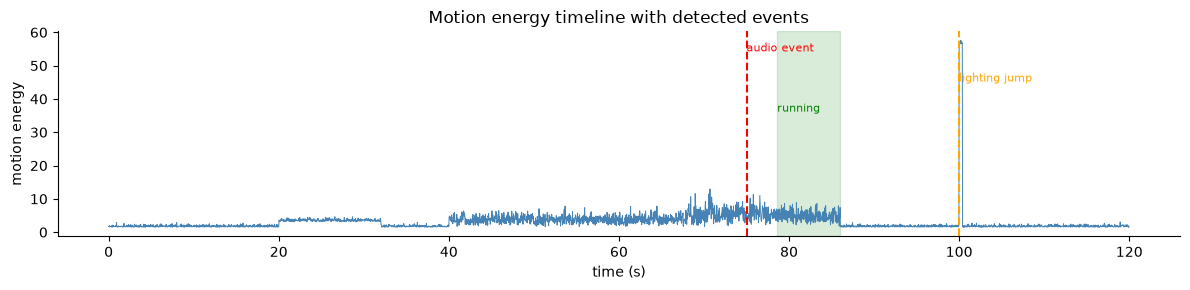

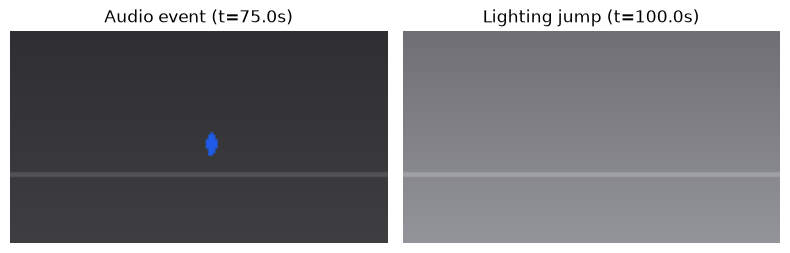

In [4]:
# TODO 1: person speed (px/s)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.sqrt(dx**2 + dy**2)

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = speed < 3
running = speed > 25

standing_times = cctv.time_s[standing.fillna(False)]
running_times = cctv.time_s[running.fillna(False)]
if len(standing_times):
    print(f"standing: {standing_times.min():.2f}s to {standing_times.max():.2f}s")
if len(running_times):
    print(f"running: {running_times.min():.2f}s to {running_times.max():.2f}s")

# TODO 3: event frame indices
audio_event_idx = cctv.index[cctv.audio_level_db > -20][0]
bjump = cctv.mean_brightness.diff().abs() > 40
lighting_event_idx = cctv.index[bjump][0]
print(f"audio event at frame {audio_event_idx} (t={cctv.time_s[audio_event_idx]:.2f}s)")
print(f"lighting event at frame {lighting_event_idx} (t={cctv.time_s[lighting_event_idx]:.2f}s)")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.7, color="steelblue")
ax.axvline(cctv.time_s[audio_event_idx], color="red", ls="--")
ax.text(cctv.time_s[audio_event_idx], ax.get_ylim()[1]*0.9, "audio event", color="red", fontsize=8)
ax.axvline(cctv.time_s[lighting_event_idx], color="orange", ls="--")
ax.text(cctv.time_s[lighting_event_idx], ax.get_ylim()[1]*0.75, "lighting jump", color="orange", fontsize=8)
if len(running_times):
    ax.axvspan(running_times.min(), running_times.max(), color="green", alpha=0.15)
    ax.text(running_times.min(), ax.get_ylim()[1]*0.6, "running", color="green", fontsize=8)
ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy")
ax.set_title("Motion energy timeline with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(render_frame(cctv.iloc[audio_event_idx])); axes[0].set_title(f"Audio event (t={cctv.time_s[audio_event_idx]:.1f}s)"); axes[0].axis("off")
axes[1].imshow(render_frame(cctv.iloc[lighting_event_idx])); axes[1].set_title(f"Lighting jump (t={cctv.time_s[lighting_event_idx]:.1f}s)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
With uniform keyframes every 20s (so at 0, 20, 40, 60, 80, 100s etc), the audio event at ~75s would most likely get missed completely since the nearest keyframes are 60 and 80, neither one lands on the actual bang. Same risk for the lighting jump - it just depends on luck whether the event timestamp happens to be close to a 20s boundary. What we did instead is content-based keyframe selection (picks frames based on where something actually happens in the signal, not a fixed interval), which is the concept the slide is pointing to - it guarantees you capture the actual moments of interest instead of hoping they line up with a arbitrary schedule.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

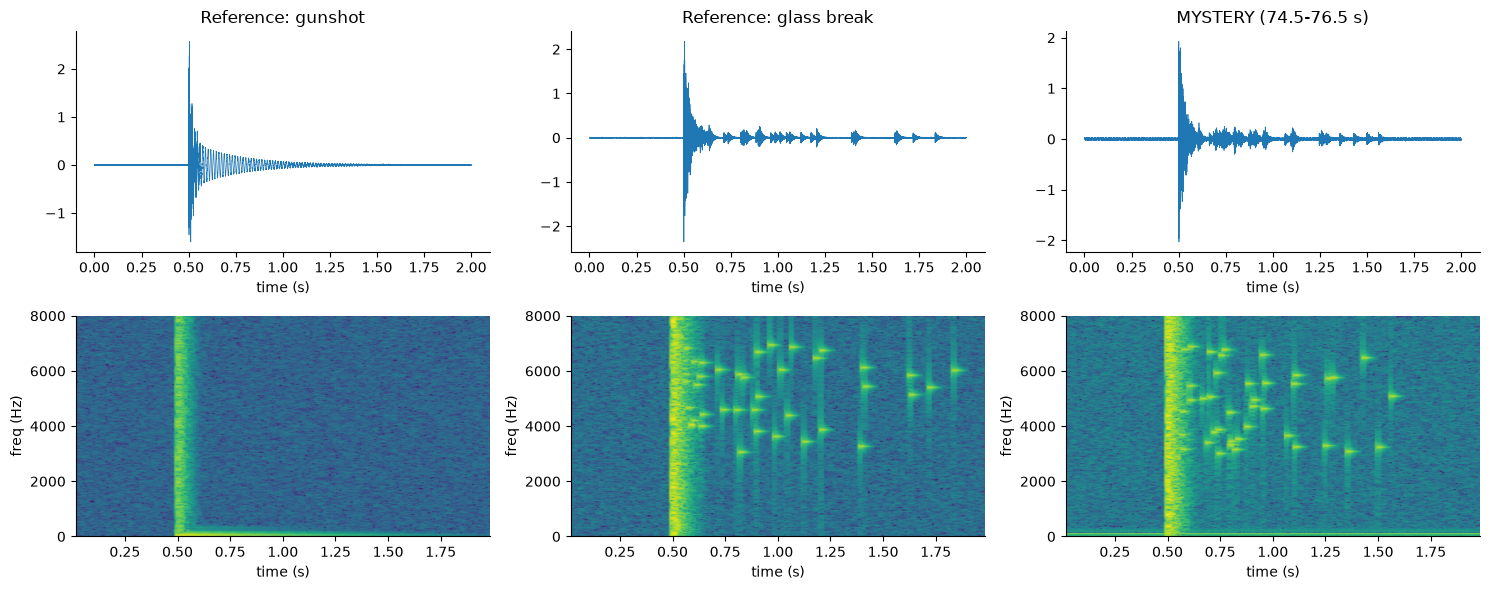

{'Reference: gunshot': np.float64(0.00327079145179223), 'Reference: glass break': np.float64(0.9896168761000713), 'MYSTERY (74.5-76.5 s)': np.float64(0.8720794440036108)}
Verdict: the mystery sound is most likely a glass break (its high-frequency energy fraction is closer to that reference).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for i, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    axes[0, i].plot(t_clip, clip, lw=0.5)
    axes[0, i].set_title(name)
    axes[0, i].set_xlabel("time (s)")

    f, t_spec, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-12)
    axes[1, i].pcolormesh(t_spec, f, Sxx_db, shading="gouraud", cmap="viridis")
    axes[1, i].set_ylim(0, 8000)
    axes[1, i].set_xlabel("time (s)"); axes[1, i].set_ylabel("freq (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    t_clip = np.arange(len(clip)) / FS
    seg = clip[(t_clip >= 0.7) & (t_clip < 1.7)]   # 0.2-1.2s after impact at t=0.5
    f, t_spec, Sxx = signal.spectrogram(seg, fs=FS, nperseg=512, noverlap=384)
    total_energy = Sxx.sum()
    hf_energy = Sxx[f > 3000].sum()
    hf_fraction[name] = hf_energy / total_energy if total_energy > 0 else 0

print(hf_fraction)
# TODO 4: verdict
mystery_hf = hf_fraction["MYSTERY (74.5-76.5 s)"]
gun_hf = hf_fraction["Reference: gunshot"]
glass_hf = hf_fraction["Reference: glass break"]
verdict = "glass break" if abs(mystery_hf - glass_hf) < abs(mystery_hf - gun_hf) else "gunshot"
print(f"Verdict: the mystery sound is most likely a {verdict} (its high-frequency energy fraction is closer to that reference).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
Honestly no, just looking at the waveforms both clips have a big spike right at the impact and then kind of random noisy wiggles after it, they look pretty similar in amplitude-over-time and I wouldn't be confident telling them apart. The spectrogram adds the frequency dimension on top of time and amplitude - so now we see time x frequency x magnitude(as color/intensity) all together instead of just time x amplitude. What decided it for me was the scattered high-frequency specks after the impact in the glass break spectrogram (that "tinkle" of broken glass shows up as little bursts of energy way up above 3kHz over almost a second), while the gunshot just has energy concentrated right at the impact and mostly dies out - and the mystery clip matches the scattered-specks pattern, not the quick-decay one.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

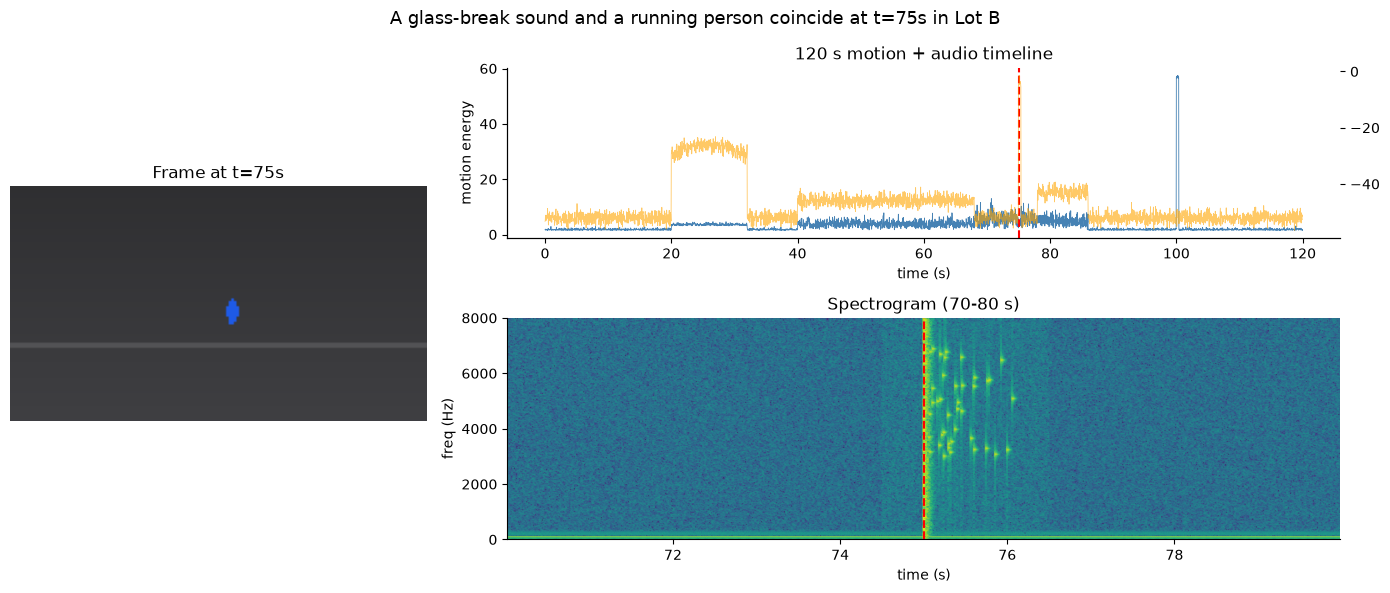

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
row_idx = (cctv.time_s - t_sel).abs().idxmin()
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[row_idx]))
ax_frame.set_title(f"Frame at t={t_sel:.0f}s")
ax_frame.axis("off")

ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv.time_s, cctv.motion_energy, lw=0.6, color="steelblue", label="motion")
ax2 = ax_timeline.twinx()
ax2.plot(cctv.time_s, cctv.audio_level_db, lw=0.6, color="orange", alpha=0.6, label="audio dB")
ax_timeline.axvline(t_sel, color="red", ls="--")
ax_timeline.set_xlabel("time (s)"); ax_timeline.set_ylabel("motion energy")
ax_timeline.set_title("120 s motion + audio timeline")

ax_spec = fig.add_subplot(gs[1, 1])
seg_mask = (t_audio >= 70) & (t_audio < 80)
f, t_spec, Sxx = signal.spectrogram(x_audio[seg_mask], fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-12)
ax_spec.pcolormesh(t_spec + 70, f, Sxx_db, shading="gouraud", cmap="viridis")
ax_spec.axvline(t_sel, color="red", ls="--")
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("time (s)"); ax_spec.set_ylabel("freq (Hz)")
ax_spec.set_title("Spectrogram (70-80 s)")

# TODO 4: conclusion-style figure title
fig.suptitle("A glass-break sound and a running person coincide at t=75s in Lot B", fontsize=13)

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
If audio was offset by +2s, the red marker at t=75s on the spectrogram would line up with the actual sound 2 seconds earlier than it really happened in the video, so the viewer would see a frame of the person just standing there while the marker says "this is when the bang happened" - which doesn't match what's on screen, making the whole briefing confusing/wrong. The spectrogram panel (bottom right) with its marker is the one that would expose this, because you could directly compare: does the loud event in the spectrogram line up at the same red line as the frame shown on the left? If not its obviously desynced.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
Around t=75s a loud bang occurred in Lot B that the spectrogram analysis matches to glass breaking rather than a gunshot (its high-frequency energy pattern lines up with the glass reference, not the gunshot reference), and this coincides with the person switching to running (roughly 78-86s) right after. I'd open the briefing with the synchronized one-screen view, because combining the frame + timeline + spectrogram together with the common time marker takes you straight from "something happened" to "here's exactly what and when" without the viewer having to mentally connect separate charts themselves - its basically the structure-to-meaning chain from the lecture compressed into one screen. For storage, I'd recommend the downsampled 360p/10fps policy for routine footage to save space, but we should NOT apply any downsampling to the full audio stream or drop it, since the audio is what let us actually identify the sound type (glass vs gunshot) here and that distinction would be impossible to tell from video alone at low resolution.